Example notebook that demonstrates how to branch from an existing run and make changes to the forcing.

You will want to create a copy of this notebook for each new branch you create. 

update (April 13, 2023):
 - helper functions have been moved to ../main_scripts/run_config_funcs.py. Please copy over the updated run_config_funcs file.

In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import os
import sys
import imp
#import re
import numpy as np
#import shutil
#from datetime import datetime
import matplotlib.pylab as plt
from scipy.interpolate import make_interp_spline

sys.path.insert(0,'../main_scripts')

import run_analysis_funcs as raf
import run_config_funcs as rcf

In [4]:
!pwd

/home/groups/earlew/nbcoffey/idealized_channel_demo/run_config


## Gather info about existing experiment

In [5]:
# specify path to existing experiment directory
# note: this experiment needs to have pickup files.
exp_dir = '/oak/stanford/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/'
exp_name_old = 'shelf_H3km_v02_noaabw'

exp_path_old = os.path.join(exp_dir, exp_name_old)


exp_name_new = exp_name_old + '_branch01_layers_yr250_monthly' 
shared_exp_dir = '/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/' # not shared anymore
exp_path_new = os.path.join(shared_exp_dir, exp_name_new)

In [6]:
# get iter# for most recent pick up year
iter_str = rcf.getPickupIter(exp_path_old)
print(iter_str)

Last iter=8044898; last iter year=250.00
0008044898


In [7]:
# get iter# for closest pick up file for some arbitrary year 
# note: the code throws an error if there is no pickup file within one year of the specified year

pickup_yr = 250 # Niall defining this variable

iter_str = rcf.getPickupIter(exp_path_old, pickup_yr=pickup_yr) #<-- specify pickup year 
print(iter_str)

Closest pickup year=250.00000126839169, iter_str=0008044898
0008044898


## Create new branch

Notes: `createNewBranch()` creates a new experiment directory that copies files from `exp_path_old` to `exp_path_new`. The `input/`, `code/`, and `build/` subdirectories are copied over in full. However, the function only copies files from the `results/` that correspond to a specific year.

In [8]:
rcf.createNewBranch(exp_path_old, exp_path_new, branch_year=pickup_yr, overwrite=True) 
#branch_year=-1 picks the most recent pickup file

copying/linking files to new exp directory. May take a few minutes...
Closest pickup year=250.00000126839169, iter_str=0008044898
Done!


## Plot old forcing

In [9]:
# load old forcing
params_old, forcing_old = raf.get_exp_params_py(exp_path_old, vname='THETA_inst')

In [10]:
taux_old = forcing_old['zonalWind']
qf_old = forcing_old['surfQ']

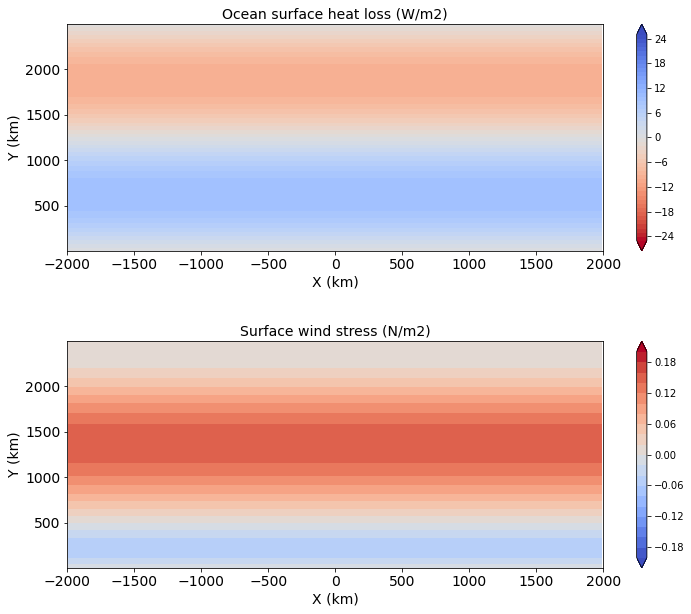

In [11]:
# plot old heat flux and wind stress


# load grid
xx = params_old['xx']
yy = params_old['yy']
XX, YY = np.meshgrid(xx, yy)


# define misc values
secsInYear = 24*3600*365
fz = 14

# plot heat flux
hf_vmin, hf_vmax = -25, 25
hf_clvls = np.arange(hf_vmin, hf_vmax+0.1, 1)


fig, axes = plt.subplots(2, 1, figsize=(12,10))

plt.sca(axes[0])
im = plt.contourf(XX/1e3, YY/1e3, qf_old, hf_clvls, vmin=hf_vmin, 
                      vmax=hf_vmax, cmap=plt.cm.coolwarm_r, extend='both')
# CS = plt.contour(XX/1e3, YY/1e3, qf_old, np.arange(25, 250, 25), 
#                      colors='k') # NBC comments 8/6/2024
# plt.clabel(CS, CS.levels, inline=True, fontsize=fz-6)

plt.xticks(np.arange(-2000, 2001, 500))
plt.tick_params(axis='both', which='major', labelsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlabel("X (km)", fontsize=fz)
plt.title("Ocean surface heat loss (W/m2)", fontsize=fz)
plt.colorbar(im, ax=axes[0])

# plot wind stress flux
ws_vmin, ws_vmax = -0.2, 0.2
ws_clvls = np.arange(ws_vmin, ws_vmax+0.001, 0.02)

plt.sca(axes[1])
im = plt.contourf(XX/1e3, YY/1e3, taux_old, ws_clvls, vmin=ws_vmin, 
                      vmax=ws_vmax, cmap=plt.cm.coolwarm, extend='both')
# plt.clabel(CS, CS.levels, inline=True, fontsize=fz-6)

plt.xticks(np.arange(-2000, 2001, 500))
plt.tick_params(axis='both', which='major', labelsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlabel("X (km)", fontsize=fz)
plt.title("Surface wind stress (N/m2)", fontsize=fz)
plt.colorbar(im, ax=axes[1])

plt.subplots_adjust(hspace=0.4)

In [12]:
print("Minimum Taux:", np.round(np.min(taux_old), 2))
print("Maximum Taux:", np.round(np.max(taux_old), 2))
print("Minimum Heat Flux:", np.min(qf_old))
print("Maximum Heat Flux:", np.max(qf_old))

Minimum Taux: -0.05
Maximum Taux: 0.15
Minimum Heat Flux: -10.0
Maximum Heat Flux: 10.0


## Create new forcing

### Update heat flux

In [13]:
# domain_params_old = params_old['domain_params'] #
# Ln = domain_params_old['L_sponge'] # length of northern sponge layer
# Ys = domain_params_old['SS_slope_Y'] # location of shelf break 

## for some reason, domain_params was not saved for this run, but the code above should generally work
# we will manually enter the domain parameters for now.
Ln = 100e3 # length of northern sponge layer <--update with the appropriate values
Ys = 300e3 # location of shelf break <--update with the appropriate values
Ly = params_old['Ly']

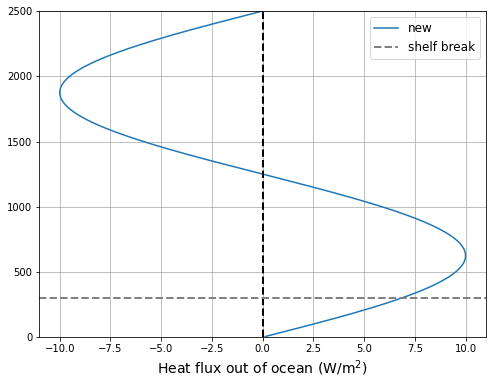

In [14]:
### note: Here and below, I copied over the code from "model_setup_exp_channel_500_250_10km" and made some updates

# #Q is ocean heat loss.
# Q_min=-10 #W/m2 peak surface warming
# Q_max=10 #W/m2 peak surface cooling
# Y_Q0=Ly*0.4 # latitude where Q = 0 W/m2

# # specify heat flux out of the ocean
# qflux_pts = {}
# qflux_pts['yy'] = np.array([0, Ys, Y_Q0, Ly*0.65, Ly-Ln, Ly])
# qflux_pts['values'] = np.array([0, Q_max*0.99, 0, Q_min*0.99, 0, 0]) 

# spl = make_interp_spline(qflux_pts['yy'], qflux_pts['values'], k=3)  # type: BSpline
# qflux = spl(yy)

# qflux[yy>(Ly-Ln)] = 0 # set forcing to zero over sponge layer


# #----------plot heat flux profile
# plt.figure(figsize=(8, 6))
# plt.plot(qflux, yy/1e3, label='new')
# plt.plot(qflux_pts['values'], qflux_pts['yy']/1e3, 'or')
# plt.axvline(0, linestyle='--', linewidth=2, color='k')
# plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
# #plt.xlim(-10, 20)
# plt.xlabel("Heat flux out of ocean (W/m$^2$)", fontsize=fz)
# plt.grid(True)
# plt.ylim(0, Ly/1e3)
# plt.legend(loc=0, fontsize=fz-2)
# ax1 = plt.gca()
# plt.show()

## NBC major comments to make the same as the actual runs you've used
q0 = 10
q0_shel_anom = 50 
Ly_shelf = Ly
q = q0*(np.sin(2*np.pi*yy/Ly)) # again use simple sinusoid
# q = q0_shel_anom*np.exp(-((yy+5e3)/Ly_shelf)**2)


#----------plot heat flux profile
plt.figure(figsize=(8, 6))
plt.plot(q, yy/1e3, label='new')
#plt.plot(qflux_pts['values'], qflux_pts['yy']/1e3, 'or')
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
#plt.xlim(-10, 20)
plt.xlabel("Heat flux out of ocean (W/m$^2$)", fontsize=fz)
plt.grid(True)
plt.ylim(0, Ly/1e3)
plt.legend(loc=0, fontsize=fz-2)
ax1 = plt.gca()
plt.show()

/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:27: MatplotlibDeprecationWarning: The 'extend' parameter to Colorbar has no effect because it is overridden by the mappable; it is deprecated since 3.3 and will be removed two minor releases later.


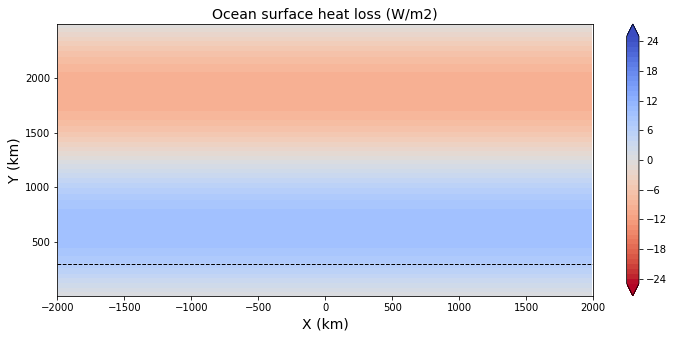

In [15]:
# expand to 2D
# qflux_2D = np.tile(qflux[np.newaxis, :], (len(xx), 1))
qflux_2D = np.tile(q[np.newaxis, :], (len(xx), 1)) # NBC edits 8/6/2024

# #add localized region of intense buoyancy loss
# Qaabw_max=150/2 # max cooling; W/m2 <--- REDUCED BY 50%
# aabw_xc = 500e3 # x location of 
# aabw_Lc = 200e3 # width of cooling region

# qflux_Ys = Qaabw_max #qflux_new_2D[yi.T].max()
# qflux_abbw = qflux_Ys*np.exp(-((XX.T-aabw_xc)/aabw_Lc)**2 - ((YY.T+5e3)/(Ys))**2)
# qflux_2D += qflux_abbw

# NBC comments out above 8/6/2024 - not doing anything with bottom water here.

plt.figure(figsize=(12,5))
vmin, vmax = -25, 25
clvls = np.arange(vmin, vmax+0.1, 1)

plt.contourf(XX/1e3, YY/1e3, qflux_2D.T, clvls, vmin=vmin, vmax=vmax, cmap=plt.cm.coolwarm_r, extend='both')
plt.axhline(Ys/1e3, linestyle='--', linewidth=1, color='k')
plt.xticks(np.arange(-2000, 2001, 500))
ax1.tick_params(axis='both', which='major', labelsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlabel("X (km)", fontsize=fz)
plt.title("Ocean surface heat loss (W/m2)", fontsize=fz)
plt.colorbar(extend='both')

# NBC comments 8/6/2024 - not doing anything with bottom water here
# cs = plt.contour(XX/1e3, YY/1e3, qflux_abbw.T, np.arange(25, 251, 25), 
#                  colors='k', vmin=vmin, vmax=vmax, extend='both')

# plt.clabel(cs, cs.levels, inline=True, fontsize=fz-2)


# xidx = np.argmin(np.abs(aabw_xc-xx))
# qflux_aabw = qflux_2D[xidx, :]    

### Update wind stress

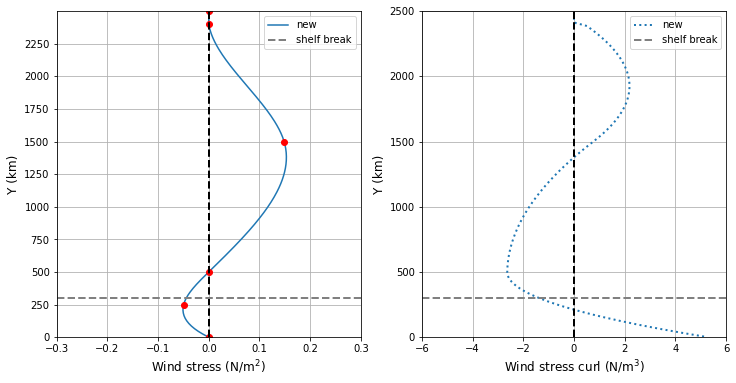

In [16]:

### note: Here and below, I copied over the code from "model_setup_exp_channel_500_250_10km" and made some updates




tau_east_max=0.15#0.2
tau_west_max=0.05
Y_tau0=Ly*0.2 # latitude where tau=0

# zonal wind stress
taux_pts = {}
taux_pts['yy'] = np.array([0, Y_tau0/2, Y_tau0, Ly*0.6,  Ly-Ln, Ly])
taux_pts['values'] = np.array([-tau_west_max*0, -tau_west_max*0.99, 0, tau_east_max*0.99, 0, 0])

spl = make_interp_spline(taux_pts['yy'], taux_pts['values'], k=3) 
taux = spl(yy)
taux[yy>(Ly-Ln)] = 0 # set forcing to zero over sponge layer


# plot wind profile

fz =12

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plt.sca(axes[0])
plt.plot(taux, yy/1e3, label='new')
plt.plot(taux_pts['values'], taux_pts['yy']/1e3, 'or')
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
plt.xlim(-0.3, 0.3)
plt.yticks(np.arange(0, 2500, 250))
plt.xlabel("Wind stress (N/m$^2$)", fontsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.grid(True)
plt.ylim(0, Ly/1e3)
plt.legend(loc=0, fontsize=fz-2)


# compute and winds stress curl
dtaux_dy = np.gradient(taux, yy, edge_order=2) 

plt.sca(axes[1])
plt.plot(-dtaux_dy*1e7, yy/1e3, ':', linewidth=2, label='new')
plt.xlabel("Wind stress curl (N/m$^3$)", fontsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlim(-6, 6)
plt.ylim(0, Ly/1e3)
plt.grid(True)
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
plt.legend(loc=0, fontsize=fz-2)
plt.subplots_adjust(hspace=0.3)
plt.show()

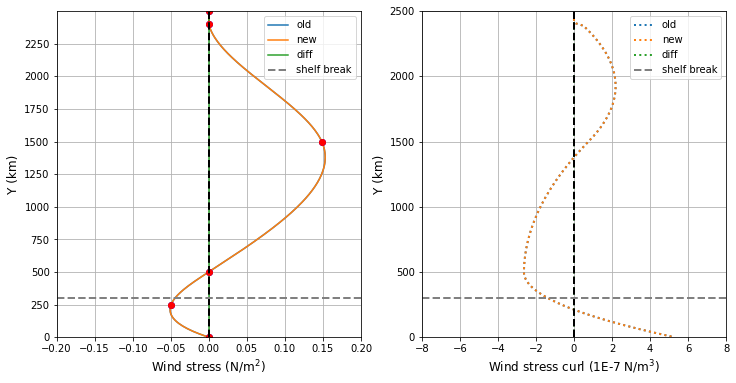

In [17]:

# old zonal wind stress
taux_pts0 = {}
taux_pts0['yy'] = np.array([0, Y_tau0/2, Y_tau0, Ly*0.6,  Ly-Ln, Ly])
taux_pts0['values'] = np.array([-tau_west_max*0, -tau_west_max*0.99, 0, tau_east_max*0.99, 0, 0])

spl0 = make_interp_spline(taux_pts0['yy'], taux_pts0['values'], k=3) 
taux0 = spl0(yy)
taux0[yy>(Ly-Ln)] = 0 # set forcing to zero over sponge layer
taux = taux0

# # perturbation profile

# shift_n = 75e3

# tau_east_max=0.15#0.2
# tau_west_max=0.05
# Y_tau0=Ly*0.2 # latitude where tau=0

# # zonal wind stress
# taux_pts = {}
# taux_pts['yy'] = np.array([0+0, Y_tau0/2, 300e3+shift_n, 900e3, 1250e3, Ly*0.6,  Ly-Ln, Ly])
# taux_pts['values'] = np.array([-tau_west_max*0, -tau_west_max*0.99, spl0(300e3), spl0(900e3), spl0(1250e3), tau_east_max*0.99, 0, 0])

# spl = make_interp_spline(taux_pts['yy'], taux_pts['values'], k=3) 
# taux = spl(yy)
# taux[yy>(Ly-Ln)] = 0 # set forcing to zero over sponge layer

# taux += bump


# plot wind profile

fz =12

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plt.sca(axes[0])
plt.plot(taux0, yy/1e3, label='old')
plt.plot(taux, yy/1e3, label='new')
plt.plot(-taux0+taux, yy/1e3, label='diff')
plt.plot(taux_pts['values'], taux_pts['yy']/1e3, 'ob')
plt.plot(taux_pts0['values'], taux_pts0['yy']/1e3, 'or')
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
plt.xlim(-0.2, 0.2)
plt.yticks(np.arange(0, 2500, 250))
plt.xlabel("Wind stress (N/m$^2$)", fontsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.grid(True)
plt.ylim(0, Ly/1e3)
plt.legend(loc=0, fontsize=fz-2)


# compute and winds stress curl
dtaux_dy = np.gradient(taux, yy, edge_order=2) 
dtaux_dy0 = np.gradient(taux0, yy, edge_order=2) 

plt.sca(axes[1])
plt.plot(-dtaux_dy0*1e7, yy/1e3, ':', linewidth=2, label='old')
plt.plot(-dtaux_dy*1e7, yy/1e3, ':', linewidth=2, label='new')
plt.plot((dtaux_dy0-dtaux_dy)*1e7, yy/1e3, ':', linewidth=2, label='diff')
plt.xlabel("Wind stress curl (1E-7 N/m$^3$)", fontsize=fz)
plt.ylabel("Y (km)", fontsize=fz)
plt.xlim(-8, 8)
plt.ylim(0, Ly/1e3)
plt.grid(True)
plt.axvline(0, linestyle='--', linewidth=2, color='k')
plt.axhline(Ys/1e3, linestyle='--', linewidth=2, color='0.5', label='shelf break')
plt.legend(loc=0, fontsize=fz-2)
plt.subplots_adjust(hspace=0.3)
plt.show()

### save new forcing files

In [18]:
taux_2D = np.tile(taux[np.newaxis, :], (len(xx), 1))


# save surface forcing

input_dir = os.path.join(exp_path_new, 'input/')

taux_fpath = os.path.join(input_dir, 'zonalWindFile.bin')
with open(taux_fpath, 'wb') as f:
    taux_2D.T.astype('>f8').tofile(f)

qflux_fpath = os.path.join(input_dir, 'surfQFile.bin')
with open(qflux_fpath, 'wb') as f:
    qflux_2D.T.astype('>f8').tofile(f)

## fast layers

In [19]:
layers_params01 = {}

### Number of fields for which to calculate layer fluxes
layers_maxNum = 1

### Specify potential temperature
layers_name = 'TH'

### Potential temperature bounds for layers 
# note: one should check to see if these levels match the range of temperatures in the domain
# also, if salinity is being evolved, the layer bounds will need to be defined by density

# original
# layers_bounds = np.hstack([np.arange(-1, 1, 0.05), np.arange(1, 3, 0.2), np.arange(3, 7.2, 0.3),
#                            np.arange(7.4, 9, 0.2), np.arange(9, 12.001, 0.1)])


layers_bounds = np.hstack([np.arange(-1, 1, 0.1), np.arange(1, 3, 0.25), np.arange(3, 9, 0.5),np.arange(9, 12.001, 1)])

# layers_bounds = np.hstack([np.arange(-1, 1, 0.05), np.arange(1, 3, 0.1), np.arange(3, 9, 0.25),
#                            np.arange(9, 12.001, 0.5)])
                           
### Reference level for calculation of potential density
layers_krho = 1    

### If set true, the GM bolus velocity is added to the calculation
# if run_config['use_GMRedi']:
#     layers_bolus = True
# else:
layers_bolus = False

### Layers
layers_params01['layers_bounds'] = layers_bounds
layers_params01['layers_krho'] = layers_krho
layers_params01['layers_name'] = layers_name
layers_params01['layers_bolus'] = layers_bolus

layers_params = [layers_params01]

### move these down
# rcf.write_data(run_config, layers_params, group_name='layers')

# # create createLAYERSSIZEh
# Nlayers = len(layers_params01['layers_bounds'])-1
# rcf.createLAYERSSIZEh(run_config, Nlayers)

## update diagnostic output

In [20]:
# Here we specify variables that should saved (i.e., written to disk) at various time intervals
update_diag_output = True#False
# adjust output frequency
if update_diag_output:
    
    inst_freq = 1/73 # 5 day intervals, e.g. 5/365 #0.5 #yrs<-----UPDATE
    tavg_freq = 1/12 # yrs<-----UPDATE


    #---------specify time averaged fields------#
    # NOTE: many more options available see mitgcm docs
#     diag_fields_avg = ['UVEL', 'VVEL', 'THETA', 'VVELTH', 'UVELTH'] #<-----UPDATE
#     diag_fields_avg = ['UVEL', 'VVEL', 'THETA',  'VVELTH', 'UVELTH', 
#                     'ETAN', 'UVELSQ', 'VVELSQ', 'WVEL']
    diag_fields_avg = ['UVEL', 'VVEL', 'WVEL', 'THETA',  'UVELTH', 'VVELTH', 'WVELTH', 
                    'ETAN', 'UVELSQ', 'VVELSQ', 'WVELSQ', 
                   'TOTTTEND', 'TFLUX', 'ADVr_TH', 'ADVx_TH', 'ADVy_TH', 
                   'DFrE_TH', 'DFxE_TH', 'DFyE_TH', 'DFrI_TH', 'oceQsw', 'WTHMASS', 
#                    'LAYERS_TH', 'LAYERS_U', 'LAYERS_V', 'LAYERS_W',
                  'LaUH1TH', 'LaVH1TH', 'LaHw1TH','LaHs1TH']

#     diag_fields_avg = ['UVEL', 'VVEL', 'WVEL', 'UVELSQ', 'VVELSQ', 'WVELSQ',
#                       'UVELTH', 'VVELTH', 'WVELTH', 'THETA', 'THETASQ',
#                       'PHIHYD', 'LaUH1TH', 'LaVH1TH', 'LaHw1TH','LaHs1TH']

    numdiags_avg = len(diag_fields_avg)
    diag_phase_avg = 0.0

    diag_freq_inst = -inst_freq*secsInYear # negative values indicate snapshots at given interval
    diag_freq_avg = tavg_freq*secsInYear # positive values indicate time average over specified interval


    diag_params01 = {}
    diag_params01['diag_mnc'] = False 

    for ii in range(numdiags_avg):  
        n = ii+1
        diag_params01['fields(1,%s)'%n] = diag_fields_avg[ii]
        diag_params01['fileName(%s)'%n] = diag_fields_avg[ii]
        diag_params01['frequency(%s)'%n] = diag_freq_avg
        diag_params01['timePhase(%s)'%n] = diag_phase_avg


    #--------specify instanteous fields (i.e. snapshots)--------#
#     diag_fields_inst = ['UVEL', 'VVEL', 'THETA',  'VVELTH', 'UVELTH'] #<-----UPDATE
#     diag_fields_inst = ['UVEL', 'VVEL', 'THETA', 'ETAN']
    diag_fields_inst = ['UVEL', 'VVEL', 'WVEL', 'THETA',  'UVELTH', 'VVELTH', 'WVELTH', 
                    'ETAN', 'UVELSQ', 'VVELSQ', 'WVELSQ', 
                   'TOTTTEND', 'TFLUX', 'ADVr_TH', 'ADVx_TH', 'ADVy_TH', 
                   'DFrE_TH', 'DFxE_TH', 'DFyE_TH', 'DFrI_TH', 'oceQsw', 'WTHMASS', 
#                    'LAYERS_TH', 'LAYERS_U', 'LAYERS_V', 'LAYERS_W',
                  'LaUH1TH', 'LaVH1TH', 'LaHw1TH','LaHs1TH']
    
    numdiags_inst = len(diag_fields_inst)
    diag_phase_inst = 0.0

    for ii in range(numdiags_inst):
        n = numdiags_avg+ii+1
        diag_params01['fields(1,%s)'%n] = diag_fields_inst[ii]
        diag_params01['fileName(%s)'%n] = diag_fields_inst[ii] + '_inst'
        diag_params01['frequency(%s)'%n] = diag_freq_inst
        diag_params01['timePhase(%s)'%n] = diag_phase_inst

    print(diag_params01)
    Ndiags = n
    
    
    
    #----update data.diagnostics file----#
    diag_params02={}
    diag_params = [diag_params01, diag_params02]
    dummy_dict = {'run_dir': exp_path_new}
    
    ### NBC moving layers down
    rcf.write_data(dummy_dict, layers_params, group_name='layers') ### swapping run_config for dummy_dict
    # create createLAYERSSIZEh
    Nlayers = len(layers_params01['layers_bounds'])-1
    rcf.createLAYERSSIZEh(dummy_dict, Nlayers)
    
    rcf.write_data(dummy_dict, diag_params, group_name='diagnostics')
    
    ## update DIAGNOSTICS_SIZE.h
    gpNr = 80 #50 # trying 50 for grid_params['Nr'].
    Nlevels = np.max([gpNr, Nlayers])
#     Nlevels = params_old['grid_params']['Nr']
    rcf.createDIAGSIZEh(dummy_dict, Ndiags, Nlevels)
    
    

{'diag_mnc': False, 'fields(1,1)': 'UVEL', 'fileName(1)': 'UVEL', 'frequency(1)': 2628000.0, 'timePhase(1)': 0.0, 'fields(1,2)': 'VVEL', 'fileName(2)': 'VVEL', 'frequency(2)': 2628000.0, 'timePhase(2)': 0.0, 'fields(1,3)': 'WVEL', 'fileName(3)': 'WVEL', 'frequency(3)': 2628000.0, 'timePhase(3)': 0.0, 'fields(1,4)': 'THETA', 'fileName(4)': 'THETA', 'frequency(4)': 2628000.0, 'timePhase(4)': 0.0, 'fields(1,5)': 'UVELTH', 'fileName(5)': 'UVELTH', 'frequency(5)': 2628000.0, 'timePhase(5)': 0.0, 'fields(1,6)': 'VVELTH', 'fileName(6)': 'VVELTH', 'frequency(6)': 2628000.0, 'timePhase(6)': 0.0, 'fields(1,7)': 'WVELTH', 'fileName(7)': 'WVELTH', 'frequency(7)': 2628000.0, 'timePhase(7)': 0.0, 'fields(1,8)': 'ETAN', 'fileName(8)': 'ETAN', 'frequency(8)': 2628000.0, 'timePhase(8)': 0.0, 'fields(1,9)': 'UVELSQ', 'fileName(9)': 'UVELSQ', 'frequency(9)': 2628000.0, 'timePhase(9)': 0.0, 'fields(1,10)': 'VVELSQ', 'fileName(10)': 'VVELSQ', 'frequency(10)': 2628000.0, 'timePhase(10)': 0.0, 'fields(1,11)'

## Next steps

You can use the extend_run notebook to push this run forward. Alternatively, you can extend the run here, by running the code below. Either way, you should use extend_run for future advances.

In [21]:
ncpus = params_old['grid_params']['nPx']*params_old['grid_params']['nPy']
wall_mins_per_sim_yr = 45 #<--- I made up an estimate

rcf.extendRun(exp_path_new, newEndYr=280, overWriteFiles=True, printNewRunScript=True, 
              results_path='', ncpus=ncpus,
              wall_mins_per_sim_yr=wall_mins_per_sim_yr, max_walltime_hrs=72)

Backing up data...
Backing up params.p...
Backing up data.diagnostics...
Backing up run_mitgcm...
Estimated runtime: 24.0 hrs
--------------------

---------------------------------
#!/bin/bash 
#SBATCH -J shelf_H3km_v02_noaabw_branch01_layers_yr250_monthly
#SBATCH -o output_%j.txt # output and error file name (%j expands to jobID)
#SBATCH -n 250   #total number of mpi tasks requested
##SBATCH --nodes=13   #total number of nodes requested
#SBATCH --constraint=CLASS:SH3_CBASE
#SBATCH --mem-per-cpu=250M
#SBATCH -p serc
#SBATCH -t 24:00:00  # run time (hh:mm:ss)
#SBATCH --mail-user=nbcoffey@stanford.edu
#SBATCH --mail-type=begin  # email me when the job starts
#SBATCH --mail-type=end  # email me when the job finishes

module load netcdf
module load openmpi/4.0.3
#module load openmpi
srun ./mitgcmuv

---------------------------------
run_mitgcm updated!
Ready to submit...
Over-writing data and param files!


In [23]:
print(exp_path_new)

/scratch/groups/earlew/nbcoffey/research/modeling/MITgcm/experiments/shelf_H3km_v02_noaabw_branch01_layers_yr250_monthly
